<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/notebooks/05_generalisation_gas_turbine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 05 — Generalisation: Gas Turbine Emissions
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems

Does the uncertainty pipeline work beyond the steel plant? This notebook applies it to a **different process with
different data**:

| | Steel plant (notebooks 01–04) | Gas turbine (this notebook) |
|---|---|---|
| Process | Electricity-driven steel finishing | Fuel-burning gas turbine (power plant, Turkey) |
| Emissions | CO₂ **calculated** from energy | NOx and CO **measured** in the flue gas |
| Task | Forecast tomorrow | Estimate this hour's emissions from sensor readings (a *software sensor*) |
| Data | 1 year, 15-min | 5 years (2011–2015), hourly, 36,733 rows |

A software sensor (Predictive Emission Monitoring System, PEMS) backs up the expensive analysers that measure flue gas.
If its estimates come with **trustworthy ranges**, operators know when to rely on it.

**Split** (as in the dataset's original paper, Kaya et al. 2019): training 2011–2012, checking (calibration) 2013,
testing 2014–2015. The original authors noted that the turbine's behaviour drifts over these years, so this is also a
hard test of calibration under change.

**Methods** — the same family as notebook 03, adapted to sensor data:

| Method | How it produces a range |
|---|---|
| A. XGBoost + conformal | Point estimate widened by the size of past errors |
| B. Low–high XGBoost | Models for the low (2.5%), middle and high (97.5%) value, then calibrated |
| C. Neural-network ensemble | Five small networks, each predicting a value and its own noise level, then calibrated |
| + Adaptive calibration | The range is adjusted hour by hour through the test years |

No GPU is needed.

## Part 0 — Setup

In [1]:
import sys, os, json, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))
PROC, FIGS, RES, MODELS = (f"{BASE}/data/processed", f"{BASE}/results/figures", f"{BASE}/results", f"{BASE}/models")
CONFIG = json.load(open(f"{BASE}/config.json"))
QUICK_TEST = os.environ.get("NB_QUICK_TEST") == "1"     # only for automated checks; leave unset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ALPHA = 1 - CONFIG["confidence"]
Q_LO, Q_HI, Q_UP = ALPHA / 2, 1 - ALPHA / 2, 1 - ALPHA
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
MCOL = {"A. XGBoost + conformal": "#0E7C7B", "B. Low–high XGBoost": "#2E6DA4", "C. Network ensemble": "#6C3FB0"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


## Part 1 — Data
Inputs are the turbine's sensor readings; outputs are the measured NOx and CO concentrations (mg/m³).

| Input | Meaning |
|---|---|
| AT, AP, AH | Ambient temperature, pressure, humidity |
| AFDP | Air filter pressure difference |
| GTEP | Gas turbine exhaust pressure |
| TIT, TAT | Turbine inlet and after-turbine temperatures |
| CDP | Compressor discharge pressure |
| TEY | Turbine energy yield (MWh) |

In [2]:
gas = pd.read_parquet(f"{PROC}/gas_prepared.parquet")
FEATS = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGETS = ["NOX", "CO"]
gas = gas.dropna(subset=FEATS + TARGETS).reset_index(drop=True)
gas["t"] = np.arange(len(gas))                  # hour index (rows are in time order within each year)
print(gas.groupby("split")["year"].agg(["min", "max", "count"]))
print(gas.groupby("year")[TARGETS + ["TEY"]].mean().round(2))

        min   max  count
split                   
calib  2013  2013   7152
test   2014  2015  14542
train  2011  2012  15039
        NOX    CO     TEY
year                     
2011  67.58  1.57  135.75
2012  68.79  2.36  132.68
2013  70.01  2.72  132.17
2014  60.07  2.08  132.91
2015  59.89  3.13  133.99


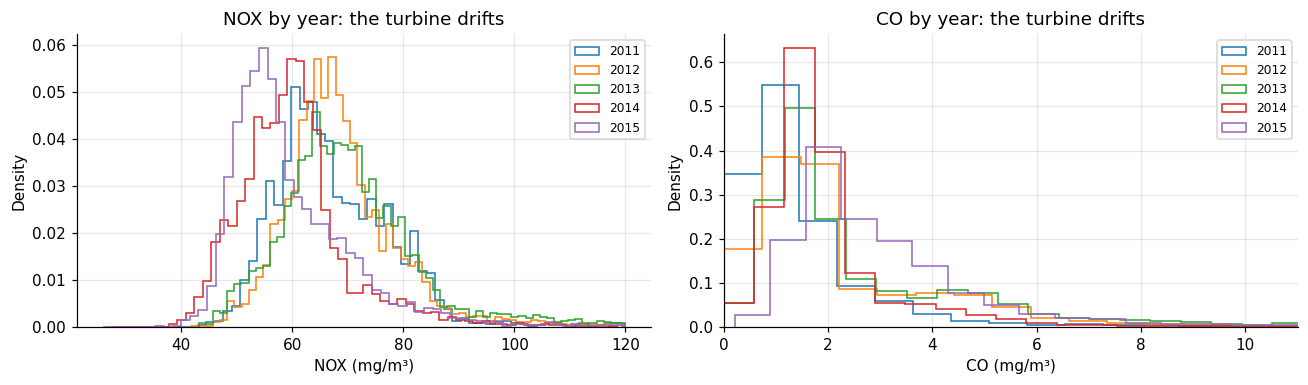

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, tgt in zip(ax, TARGETS):
    for yr, g in gas.groupby("year"):
        a.hist(g[tgt], bins=60, histtype="step", lw=1.3, density=True, label=str(yr))
    a.set(xlabel=f"{tgt} (mg/m³)", ylabel="Density", title=f"{tgt} by year: the turbine drifts")
    a.legend(fontsize=8)
ax[1].set_xlim(0, np.percentile(gas["CO"], 99))
savefig("05_target_drift")

## Part 2 — Calibration tools (same as notebook 03)

In [4]:
def conformal_level(n, alpha):
    return min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)

def q_two_sided(lo, hi, y, alpha=ALPHA):
    s = np.maximum(lo - y, y - hi)
    return np.quantile(s, conformal_level(len(s), alpha), method="higher")

def q_upper(up, y, alpha=ALPHA):
    s = y - up
    return np.quantile(s, conformal_level(len(s), alpha), method="higher")

def interval_score(lo, hi, y, alpha=ALPHA):
    return (hi - lo) + (2 / alpha) * (lo - y) * (y < lo) + (2 / alpha) * (y - hi) * (y > hi)

TR, CA, TE = (gas["split"] == "train").values, (gas["split"] == "calib").values, (gas["split"] == "test").values
# Early stopping uses the last 20% of the training years (never the checking or test years)
cut = gas.loc[TR, "t"].quantile(0.8)
FIT, VAL = TR & (gas["t"] <= cut).values, TR & (gas["t"] > cut).values
print("Rows | fit:", FIT.sum(), "early-stop:", VAL.sum(), "checking:", CA.sum(), "test:", TE.sum())

Rows | fit: 12031 early-stop: 3008 checking: 7152 test: 14542


## Part 3 — Fit the three methods for NOx and CO

In [5]:
X = gas[FEATS].values.astype(np.float32)
mu_x, sd_x = X[FIT].mean(0), X[FIT].std(0) + 1e-6
Xs = (X - mu_x) / sd_x

def xgb_fit(y, objective="reg:squarederror", q=None):
    kw = dict(n_estimators=3000, learning_rate=0.03, max_depth=6, min_child_weight=5, subsample=0.8,
              colsample_bytree=0.9, early_stopping_rounds=100, random_state=SEED)
    if q is None:
        m = xgb.XGBRegressor(objective=objective, **kw)
    else:
        m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=q, **kw)
    m.fit(X[FIT], y[FIT], eval_set=[(X[VAL], y[VAL])], verbose=False)
    return m.predict(X)

class GaussNet(nn.Module):
    def __init__(self, d, h=64, p=0.1):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, h), nn.ReLU(), nn.Dropout(p))
        self.out = nn.Linear(h, 2)
    def forward(self, x):
        o = self.out(self.body(x))
        return o[:, 0], o[:, 1].clamp(-10, 6)

def net_fit(y, seed, epochs, patience=15, batch=256):
    torch.manual_seed(seed)
    ym, ys = y[FIT].mean(), y[FIT].std()
    xt = torch.tensor(Xs); yt = torch.tensor(((y - ym) / ys).astype(np.float32))
    xf, yf, xv, yv = xt[FIT].to(DEVICE), yt[FIT].to(DEVICE), xt[VAL].to(DEVICE), yt[VAL].to(DEVICE)
    net = GaussNet(X.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    nll = nn.GaussianNLLLoss()
    best, state, wait = np.inf, None, 0
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(xf), device=DEVICE)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            m_, lv = net(xf[idx]); loss = nll(m_, yf[idx], lv.exp())
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            m_, lv = net(xv); v = nll(m_, yv, lv.exp()).item()
        if v < best - 1e-5:
            best, state, wait = v, {k: t.detach().cpu().clone() for k, t in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(state); net.eval()
    with torch.no_grad():
        m_, lv = net(xt.to(DEVICE))
    return m_.cpu().numpy() * ys + ym, lv.exp().cpu().numpy() * ys ** 2

N_MEMBERS = 2 if QUICK_TEST else 5
EPOCHS = 3 if QUICK_TEST else 300
OUT = {}
t0 = time.time()
for tgt in TARGETS:
    y = gas[tgt].values.astype(np.float32)
    o = {}
    p = xgb_fit(y); o["A. XGBoost + conformal"] = (p, p, p, p)
    qs = np.sort(np.column_stack([xgb_fit(y, q=q) for q in (Q_LO, 0.5, Q_UP, Q_HI)]), axis=1)
    o["B. Low–high XGBoost"] = (qs[:, 1], qs[:, 0], qs[:, 3], qs[:, 2])
    mus, vs = zip(*[net_fit(y, SEED + k, EPOCHS) for k in range(N_MEMBERS)])
    mus, vs = np.stack(mus), np.stack(vs)
    mean = mus.mean(0); var = vs.mean(0) + mus.var(0)
    sd = np.sqrt(var); z_lo, z_up = 1.959964, 1.644854
    o["C. Network ensemble"] = (mean, mean - z_lo * sd, mean + z_lo * sd, mean + z_up * sd)
    o["_split"] = (vs.mean(0).mean(), mus.var(0).mean())
    OUT[tgt] = o
    print(f"{tgt}: fitted in {time.time()-t0:.0f}s | ensemble uncertainty from measurement noise: "
          f"{o['_split'][0] / sum(o['_split']):.0%}")

NOX: fitted in 45s | ensemble uncertainty from measurement noise: 90%
CO: fitted in 82s | ensemble uncertainty from measurement noise: 98%


## Part 4 — Calibrate on 2013, test on 2014–2015

In [6]:
rows, CAL = [], {}
for tgt in TARGETS:
    y = gas[tgt].values
    for name in MCOL:
        point, lo, hi, up = OUT[tgt][name]
        q2, q1 = q_two_sided(lo[CA], hi[CA], y[CA]), q_upper(up[CA], y[CA])
        CAL[(tgt, name)] = dict(point=point, lo=lo - q2, hi=hi + q2, up=up + q1, lo_raw=lo, hi_raw=hi, up_raw=up)
        for stage, (L, Hh, U) in {"raw": (lo, hi, up), "calibrated": (lo - q2, hi + q2, up + q1)}.items():
            for yr in [2014, 2015]:
                k = TE & (gas["year"] == yr).values
                rows.append({"target": tgt, "method": name, "stage": stage, "year": yr,
                             "point MAE": np.mean(np.abs(point[k] - y[k])),
                             "R²": 1 - np.sum((point[k] - y[k]) ** 2) / np.sum((y[k] - y[k].mean()) ** 2),
                             "coverage (%)": 100 * np.mean((y[k] >= L[k]) & (y[k] <= Hh[k])),
                             "width": np.mean(Hh[k] - L[k]),
                             "interval score": np.mean(interval_score(L[k], Hh[k], y[k])),
                             "above upper bound (%)": 100 * np.mean(y[k] > U[k])})
G = pd.DataFrame(rows)
G.to_csv(f"{RES}/05_gas_turbine_metrics.csv", index=False)
show = G[G.stage == "calibrated"].set_index(["target", "year", "method"]).drop(columns="stage")
print("CALIBRATED ranges, test years:")
print(show.round(3).to_string())

CALIBRATED ranges, test years:
                                    point MAE     R²  coverage (%)   width  interval score  above upper bound (%)
target year method                                                                                               
NOX    2014 A. XGBoost + conformal     10.299 -0.331        88.474  31.697          50.923                  1.676
       2015 A. XGBoost + conformal     11.176 -0.268        78.277  31.697          61.045                  0.095
       2014 B. Low–high XGBoost         9.863 -0.242        93.727  33.732          41.791                  1.900
       2015 B. Low–high XGBoost        10.844 -0.212        89.748  34.218          44.366                  0.095
       2014 C. Network ensemble         9.161 -0.056        95.516  34.870          40.905                  1.509
       2015 C. Network ensemble        10.729 -0.120        89.112  36.054          44.722                  0.054
CO     2014 A. XGBoost + conformal      0.893  0.180     

**How to read this.** Coverage should be near 95% and *above upper bound* near 5%. Because the turbine drifts after
2013, a fixed calibration may hold in 2014 but slip in 2015. Part 5 tests whether adaptive calibration fixes this.

## Part 5 — Adaptive calibration through 2014–2015
The range is updated **hour by hour**: after an hour outside the range, the next range widens; after an hour inside, it
narrows slightly (Gibbs & Candès, 2021; step size 0.005 for hourly data).

In [7]:
GAMMA = 0.005

def adaptive_two_sided(lo, hi, y):
    # returns calibrated lo/hi for test hours, updating one hour at a time
    scores = list(np.maximum(lo[CA] - y[CA], y[CA] - hi[CA]))
    idx = np.where(TE)[0]
    a_t, L, U, miss = ALPHA, np.empty(len(idx)), np.empty(len(idx)), np.empty(len(idx))
    sc = np.array(scores, dtype=float)
    buf = np.empty(len(sc) + len(idx)); buf[:len(sc)] = sc; n = len(sc)
    for j, i in enumerate(idx):
        if a_t <= 0:
            q = buf[:n].max() * 1.2
        elif a_t >= 1:
            q = -np.inf
        else:
            q = np.quantile(buf[max(0, n - 8760):n], min(1, 1 - a_t), method="higher")   # last year of scores
        L[j], U[j] = lo[i] - q, hi[i] + q
        miss[j] = float((y[i] < L[j]) or (y[i] > U[j]))
        a_t += GAMMA * (ALPHA - miss[j])
        buf[n] = max(lo[i] - y[i], y[i] - hi[i]); n += 1
    return L, U, miss

ADAPT, rows = {}, []
for tgt in TARGETS:
    y = gas[tgt].values
    for name in MCOL:
        c = CAL[(tgt, name)]
        L, U, miss = adaptive_two_sided(c["lo_raw"], c["hi_raw"], y)
        ADAPT[(tgt, name)] = (L, U, miss)
        yt, yr = y[TE], gas.loc[TE, "year"].values
        for year in [2014, 2015]:
            k = yr == year
            fixed_cov = 100 * np.mean((yt[k] >= c["lo"][TE][k]) & (yt[k] <= c["hi"][TE][k]))
            rows.append({"target": tgt, "method": name, "year": year,
                         "fixed: coverage (%)": fixed_cov, "adaptive: coverage (%)": 100 * (1 - miss[k].mean()),
                         "fixed: width": np.mean(c["hi"][TE][k] - c["lo"][TE][k]),
                         "adaptive: width": np.mean(U[k] - L[k])})
AD = pd.DataFrame(rows)
AD.to_csv(f"{RES}/05_gas_turbine_adaptive.csv", index=False)
print(AD.set_index(["target", "year", "method"]).round(2).to_string())

                                    fixed: coverage (%)  adaptive: coverage (%)  fixed: width  adaptive: width
target year method                                                                                            
NOX    2014 A. XGBoost + conformal                88.47                   95.05         31.70            34.85
       2015 A. XGBoost + conformal                78.28                   94.88         31.70            36.71
       2014 B. Low–high XGBoost                   93.73                   95.49         33.73            31.37
       2015 B. Low–high XGBoost                   89.75                   94.49         34.22            31.45
       2014 C. Network ensemble                   95.52                   95.38         34.87            31.04
       2015 C. Network ensemble                   89.11                   94.50         36.05            33.10
CO     2014 A. XGBoost + conformal                96.74                   94.90          6.33             5.48
 

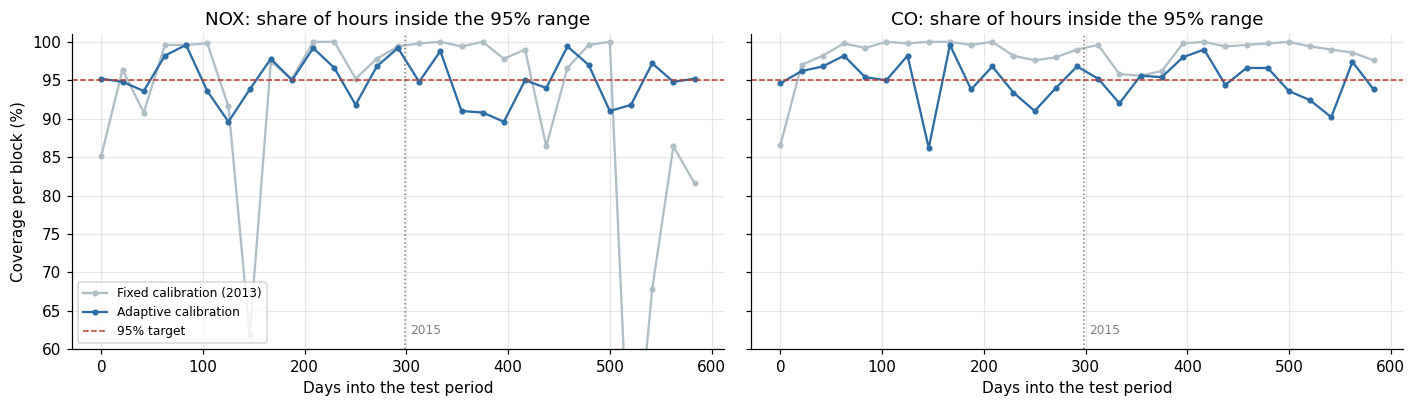

In [8]:
# Rolling coverage through the test years (blocks of about three weeks)
BLOCK = 500
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, tgt in zip(ax, TARGETS):
    y = gas.loc[TE, tgt].values
    name = "B. Low–high XGBoost"
    c = CAL[(tgt, name)]; L, U, miss = ADAPT[(tgt, name)]
    inside_fixed = (y >= c["lo"][TE]) & (y <= c["hi"][TE])
    nb = len(y) // BLOCK
    xs = np.arange(nb) * BLOCK / 24
    a.plot(xs, [100 * inside_fixed[i*BLOCK:(i+1)*BLOCK].mean() for i in range(nb)], "o-", ms=3,
           color="#B0BEC5", label="Fixed calibration (2013)")
    a.plot(xs, [100 * (1 - miss[i*BLOCK:(i+1)*BLOCK].mean()) for i in range(nb)], "o-", ms=3,
           color=MCOL[name], label="Adaptive calibration")
    a.axhline(95, color="#C0392B", ls="--", lw=1, label="95% target")
    yr_change = np.argmax(gas.loc[TE, "year"].values == 2015) / 24
    a.axvline(yr_change, color="grey", ls=":", lw=1); a.text(yr_change + 5, 62, "2015", fontsize=8, color="grey")
    a.set(xlabel="Days into the test period", title=f"{tgt}: share of hours inside the 95% range", ylim=(60, 101))
ax[0].set_ylabel("Coverage per block (%)"); ax[0].legend(fontsize=8, loc="lower left")
savefig("05_rolling_coverage")

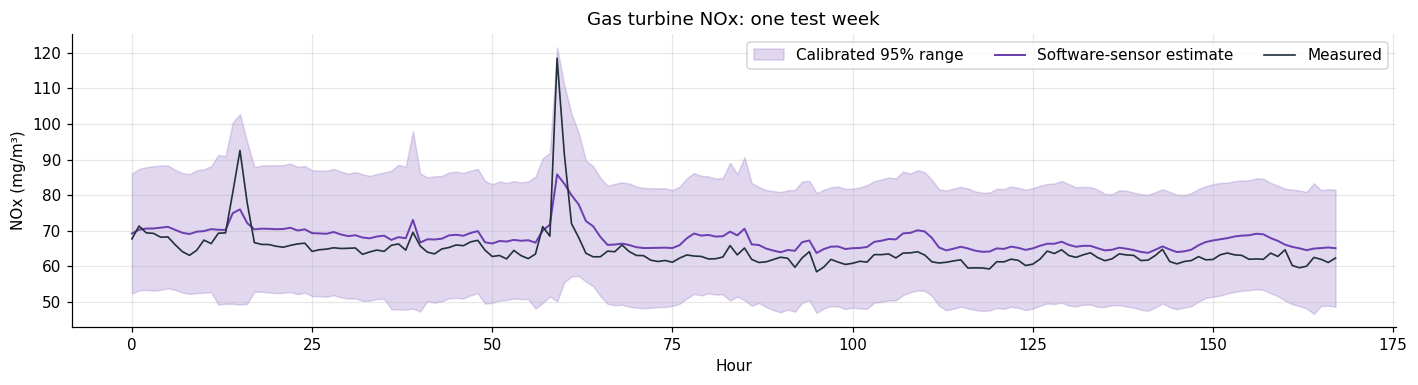

In [9]:
# One test week for NOx: estimate with calibrated range
tgt, name = "NOX", "C. Network ensemble"
c = CAL[(tgt, name)]
idx = np.where(TE)[0][2000:2000 + 168]
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.fill_between(range(168), c["lo"][idx], c["hi"][idx], color=MCOL[name], alpha=0.2, label="Calibrated 95% range")
ax.plot(range(168), c["point"][idx], color=MCOL[name], lw=1.3, label="Software-sensor estimate")
ax.plot(range(168), gas[tgt].values[idx], color="#23313B", lw=1.1, label="Measured")
ax.set(xlabel="Hour", ylabel="NOx (mg/m³)", title="Gas turbine NOx: one test week"); ax.legend(ncol=3)
savefig("05_nox_week")

## Part 6 — Do the ranges adapt to conditions?
A useful range is **wider when the turbine is harder to predict**. Here the test hours are grouped by turbine load
(TEY) and the average width of the calibrated range is shown for each group.

In [10]:
rows = []
tey = gas.loc[TE, "TEY"].values
bins = np.quantile(tey, [0, 0.25, 0.5, 0.75, 1])
grp = np.digitize(tey, bins[1:-1])
labels = ["low load", "medium-low", "medium-high", "high load"]
for tgt in TARGETS:
    y = gas.loc[TE, tgt].values
    for name in MCOL:
        c = CAL[(tgt, name)]
        w = c["hi"][TE] - c["lo"][TE]
        for gi, lab in enumerate(labels):
            k = grp == gi
            rows.append({"target": tgt, "method": name, "load": lab, "width": w[k].mean(),
                         "error": np.mean(np.abs(c["point"][TE][k] - y[k]))})
LW = pd.DataFrame(rows)
print(LW.pivot_table(index=["target", "method"], columns="load", values="width")[labels].round(2).to_string())

load                           low load  medium-low  medium-high  high load
target method                                                              
CO     A. XGBoost + conformal      6.33        6.33         6.33       6.33
       B. Low–high XGBoost         6.70        8.22         7.77       5.23
       C. Network ensemble         7.77        5.41         4.82       3.69
NOX    A. XGBoost + conformal     31.70       31.70        31.70      31.70
       B. Low–high XGBoost        38.95       33.55        32.62      30.80
       C. Network ensemble        43.21       34.78        33.18      30.72


Method A has the **same width everywhere** (one correction for all hours). Methods B and C should give wider ranges at
loads where the error is larger, which is what makes their ranges more informative.

## Part 7 — Summary for the thesis

In [11]:
for tgt in TARGETS:
    s = G[(G.target == tgt) & (G.stage == "calibrated")].groupby("method")[
        ["coverage (%)", "interval score", "point MAE"]].mean()
    best = s["interval score"].idxmin()
    a = AD[(AD.target == tgt) & (AD.method == best)][["fixed: coverage (%)", "adaptive: coverage (%)"]].mean()
    raw = G[(G.target == tgt) & (G.stage == "raw") & (G.method == best)]["coverage (%)"].mean()
    print(f"{tgt}: best method = {best}")
    print(f"     coverage raw {raw:.1f}% -> calibrated {s.loc[best, 'coverage (%)']:.1f}% "
          f"-> adaptive {a['adaptive: coverage (%)']:.1f}% (target 95%) | point MAE {s.loc[best, 'point MAE']:.2f} mg/m³")

NOX: best method = C. Network ensemble
     coverage raw 58.6% -> calibrated 92.3% -> adaptive 94.9% (target 95%) | point MAE 9.94 mg/m³
CO: best method = C. Network ensemble
     coverage raw 91.3% -> calibrated 94.6% -> adaptive 95.0% (target 95%) | point MAE 0.93 mg/m³


### Save to GitHub
File → **Save a copy in GitHub** → `notebooks/05_generalisation_gas_turbine.ipynb`
Commit message: *Notebook 05: generalisation to gas turbine NOx/CO with calibrated ranges*

### Next
**Notebook 06 — Final results:** sensitivity studies (emission limit 2.1 / 5.5 / 9.3%, flexible share and window,
"production plan known" scenario) and the final thesis tables and figures.